<a href="https://colab.research.google.com/github/masumeaslanii/ML2026/blob/main/udlbook/Ch10_1_Convolutional_Networks.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
x = [5.2, 5.3, 5.9, 5.1, 10.1, 10.3, 9.5, 10.3, 2.9, 3.4, 3.3, 3.9]

# Visualization

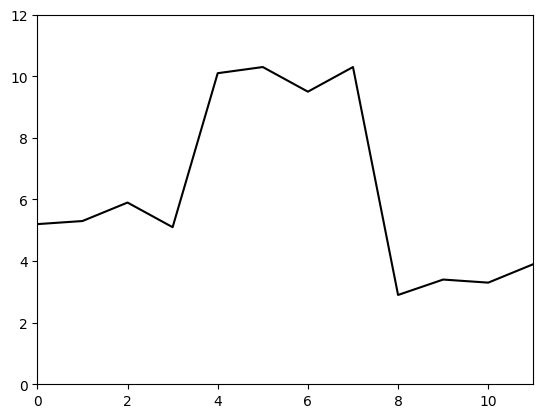

In [ ]:
fig, ax = plt.subplots()
ax.plot(x,'k-')
ax.set_xlim(0,11)
ax.set_ylim(0,12)
plt.show()

# Define a zero-padded convolution operation with a convolution kernel size of 3, a stride of 1, and a dilation of 1

In [ ]:
def conv_3_1_1_zp(x_in, omega):
  x_out = np.zeros_like(x_in)
  x_padded = np.pad(x_in, (1,1), mode= 'constant', constant_values=0)
  for i in range(len(x_in)):
    x_out[i] = (
        x_padded[i]*omega[0] + x_padded[i+1]*omega[1] + x_padded[i+2]*omega[2]
    )
  return x_out

## Example 1

In [ ]:
omega1 = (1/3, 1/3, 1/3)
h1 = conv_3_1_1_zp(x, omega1)
h1

array([ 3.5       ,  5.46666667,  5.43333333,  7.03333333,  8.5       ,
        9.96666667, 10.03333333,  7.56666667,  5.53333333,  3.2       ,
        3.53333333,  2.4       ])

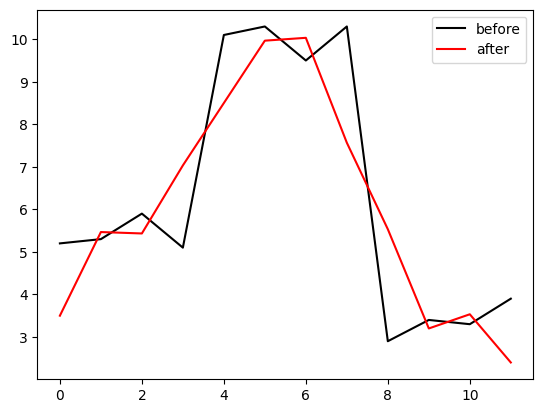

In [ ]:
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h1, 'r-',label='after')
ax.legend()
plt.show()

The first and last outputs are considerably lower because of Zero Padding. Since zeros are added at both ends of the input signal, the convolution kernel includes a zero when calculating the boundary values. This reduces the average at the beginning and end of the output signal. This effect is known as the **Boundary Effect**.

## Example 2

In [ ]:
omega2 = (-0.5, 0, 0.5)
h2 = conv_3_1_1_zp(x, omega2)
h2

array([ 2.65,  0.35, -0.1 ,  2.1 ,  2.6 , -0.3 ,  0.  , -3.3 , -3.45,
        0.2 ,  0.25, -1.65])

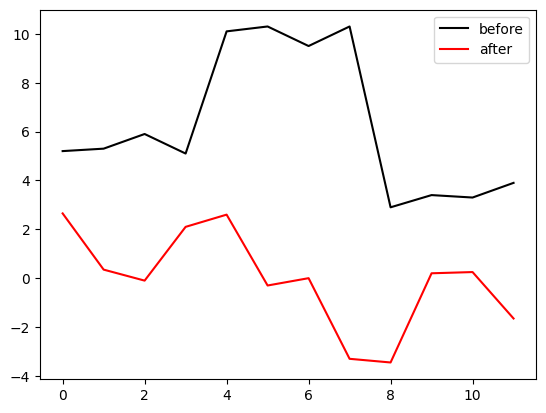

In [ ]:
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h2, 'r-',label='after')
ax.legend()
plt.show()

The kernel detects changes in the signal. When the signal increases, the output becomes positive (peak); when it decreases, the output becomes negative (trough). When the signal is locally flat, the output is approximately zero. Therefore, the convolution approximates the **first derivative** of the signal.

# Define a zero-padded convolution operation with a convolution kernel size of 3, a stride of 2, and a dilation of 1

In [ ]:
def conv_3_2_1_zp(x_in, omega):
  x_out = np.zeros(int(np.ceil(len(x_in)/2)))
  x_padded = np.pad(x_in, (1,1), mode= 'constant', constant_values=0)
  for i in range(len(x_out)):
    x_out[i] = (
        x_padded[2*i]*omega[0] + x_padded[2*i+1]*omega[1] + x_padded[2*i+2]*omega[2]
    )
  return x_out

## Example 3

In [ ]:
omega1 = (1/3, 1/3, 1/3)
h3 = conv_3_2_1_zp(x, omega1)

In [ ]:
print(f'h is {h1}')
print(f'h_3 is {h3}')

h is [ 3.5         5.46666667  5.43333333  7.03333333  8.5         9.96666667
 10.03333333  7.56666667  5.53333333  3.2         3.53333333  2.4       ]
h_3 is [ 3.5         5.43333333  8.5        10.03333333  5.53333333  3.53333333]


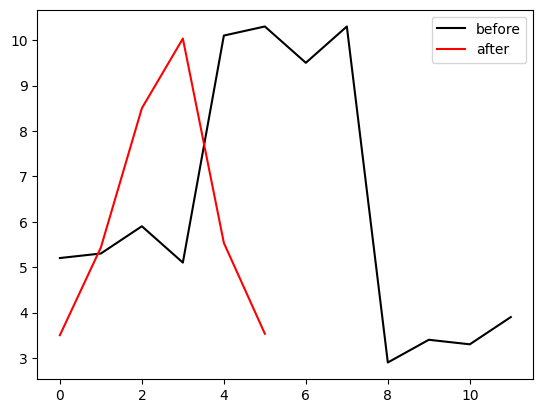

In [ ]:
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h3, 'r-',label='after')
ax.legend()
plt.show()

# Define a zero-padded convolution operation with a convolution kernel size of 5, a stride of 1, and a dilation of 1

In [ ]:
def conv_5_1_1_zp(x_in, omega):
  x_out = np.zeros_like(x_in)
  x_padded = np.pad(x_in, (1,1), mode= 'constant', constant_values=0)
  for i in range(len(x_in)):
    x_out[i] = (
        x_padded[i]*omega[0] + x_padded[i+1]*omega[1] + x_padded[i+2]*omega[2]
    )
  return x_out

## Example 4

In [ ]:
omega3 = [0.2, 0.2, 0.2, 0.2, 0.2]
h4 = conv_5_1_1_zp(x,omega3)

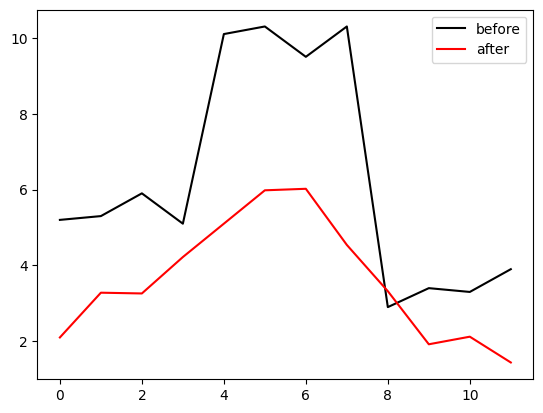

In [ ]:
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h4, 'r-',label='after')
ax.legend()
plt.show()

# Define a zero-padded convolution operation with a convolution kernel size of 3, a stride of 1, and a dilation of 2

In [ ]:
def conv_3_1_2_zp(x_in, omega):
  x_out = np.zeros_like(x_in)
  x_padded = np.pad(x_in, (2,2), mode= 'constant', constant_values=0)
  for i in range(len(x_in)):
    x_out[i] = (
        x_padded[i]*omega[0] + x_padded[i+2]*omega[1] + x_padded[i+4]*omega[2]
    )
  return x_out

## Example 5

In [ ]:
omega1 = (1/3, 1/3, 1/3)
h5 = conv_3_1_2_zp(x, omega1)

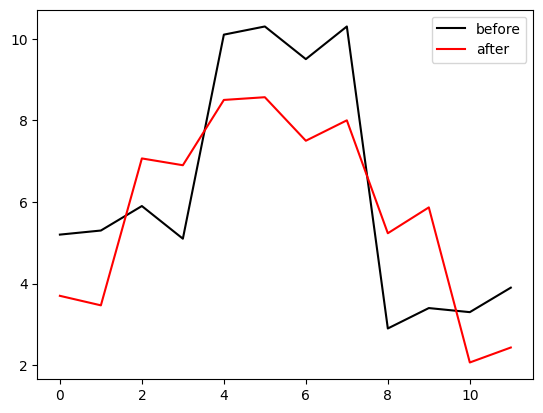

In [ ]:
fig,ax = plt.subplots()
ax.plot(x, 'k-',label='before')
ax.plot(h5, 'r-',label='after')
ax.legend()
plt.show()

# Define a zero-padded convolution **matrix** with a kernel size of 3, a stride of 1, and a dilation of 1.

In [ ]:
def get_conv_mat_3_1_1_zp(n_out, omega):
    omega_mat = np.zeros((n_out, n_out))

    for i in range(n_out):
        for j in range(n_out):
            if 0 <= j - i + 1 < 3:
                omega_mat[i, j] = omega[j - i + 1]

    return omega_mat

## Example 6

In [ ]:
omega4 = np.array([-1.0,0.5,-0.2])
h6 = conv_3_1_1_zp(x, omega4)
h6

array([ 1.54, -3.73, -3.37, -5.37, -2.11, -6.85, -7.61, -4.93, -9.53,
       -1.86, -2.53, -1.35])

In [ ]:
omega_mat = get_conv_mat_3_1_1_zp(len(x), omega4)
h7 = omega_mat @ x
h7

array([ 1.54, -3.73, -3.37, -5.37, -2.11, -6.85, -7.61, -4.93, -9.53,
       -1.86, -2.53, -1.35])

The convolution operation is implemented using two different approaches:

- **Direct Convolution:** The kernel slides over the input signal, and the output is calculated using a `for` loop.
- **Matrix Multiplication:** A convolution matrix is constructed from the kernel weights, and the output is calculated by multiplying this matrix by the input signal.

The convolution matrix is a **tridiagonal matrix**, meaning that its non-zero elements are located on the main diagonal and the two adjacent diagonals.

Both methods produce the same output, demonstrating that convolution can also be represented as a matrix multiplication:


\\[ h = \Omega x \\]

---

Applying the same convolution twice is equivalent to applying the convolution matrix twice:

$$
h_{\text{final}} = \Omega(\Omega x) = \Omega^2 x
$$

This can be represented as a single convolution with a new kernel, obtained by convolving the original kernel with itself.

For the given kernel:

```python
omega = np.array([-1.0, 0.5, -0.2])
omega_new = np.convolve(omega, omega)
```

The resulting kernel is:

```python
[1.0, -1.0, 0.65, -0.2, 0.04]
```

Therefore, applying a convolution with a kernel of size 3 twice is equivalent to applying a single convolution with a kernel of size 5.

**Note:** This equivalence assumes consistent boundary handling. With Zero Padding, the padding and output dimensions must be handled carefully.

#